# Figure 5

In this notebook, we'll generate figure panels for use in Figure 6, the overview of Dexamethasone treatment results.

For the UMAP plots, see the notebook for Figure 1. In this notebook, we'll generate the differential result barplots, Hallmark Pathway heatmaps, and motif enrichment volcano plots.

## Load packages

hise: The Human Immune System Explorer R SDK package  
purrr: Functional programming tools  
dplyr: Dataframe handling functions  
ggplot2: plotting functions  
ggrepel: text plotting with repulsion  
cowplot: multi-panel plot assembly

In [1]:
quiet_library <- function(...) { suppressPackageStartupMessages(library(...)) }
quiet_library(hise)
quiet_library(purrr)
quiet_library(dplyr)
quiet_library(ggplot2)
quiet_library(ggrepel)
quiet_library(cowplot)

Warning message:
“package ‘purrr’ was built under R version 4.4.3”
Warning message:
“package ‘dplyr’ was built under R version 4.4.3”
Warning message:
“package ‘ggplot2’ was built under R version 4.4.3”
Warning message:
“package ‘ggrepel’ was built under R version 4.4.3”
Warning message:
“package ‘cowplot’ was built under R version 4.4.3”


In [2]:
out_dir <- "output/figure_5"
if(!dir.exists(out_dir)) { dir.create(out_dir, recursive = TRUE) }

## Retrieve files

Now, we'll use the HISE SDK package to retrieve the analysis results for DEG, Hallmark Pathway enrichment, and motif enrichment.

DEG: Differentially expressed genes

In [3]:
deg_uuid <- list("fc83b89f-fd26-43b8-ac91-29c539703a45")

In [4]:
deg_file <- cacheFiles(deg_uuid)

[2026-11-06 14:37:36] INFO  Calling cacheFiles
[1] "downloading fileID fc83b89f-fd26-43b8-ac91-29c539703a45"
[2026-11-06 14:37:41] INFO  Finished cacheFiles successfully (time_elapsed=2.303s)


DEP: Differentially expressed proteins (ADT)

In [5]:
dep_uuid <- list("4cbaa9ab-f8ef-495d-ac5e-1f1d99d33e33")

In [6]:
dep_file <- cacheFiles(dep_uuid)

[2026-11-06 14:37:41] INFO  Calling cacheFiles
[1] "downloading fileID 4cbaa9ab-f8ef-495d-ac5e-1f1d99d33e33"
[2026-11-06 14:37:45] INFO  Finished cacheFiles successfully (time_elapsed=1.883s)


DAP: Differentially accessible peaks (ATAC)

In [7]:
dap_uuid <- list("a8973524-cc71-40d5-8edf-3d6a9e0a77d4")

In [8]:
dap_file <- cacheFiles(dap_uuid)

[2026-11-06 14:37:45] INFO  Calling cacheFiles
[1] "downloading fileID a8973524-cc71-40d5-8edf-3d6a9e0a77d4"
[2026-11-06 14:37:49] INFO  Finished cacheFiles successfully (time_elapsed=1.846s)


In [9]:
hallmark_uuid <- list("4f05f2a0-59d2-4d04-b948-70d541613e71")

In [10]:
hallmark_file <- cacheFiles(hallmark_uuid)

[2026-11-06 14:37:49] INFO  Calling cacheFiles
[1] "downloading fileID 4f05f2a0-59d2-4d04-b948-70d541613e71"
[2026-11-06 14:37:56] INFO  Finished cacheFiles successfully (time_elapsed=2.031s)


In [11]:
dem_uuid <- list("42adb44f-71d2-4d8b-a80c-73b0833d6a1d")

In [12]:
dem_file <- cacheFiles(dem_uuid)

[2026-11-06 14:37:56] INFO  Calling cacheFiles
[1] "downloading fileID 42adb44f-71d2-4d8b-a80c-73b0833d6a1d"
[2026-11-06 14:38:01] INFO  Finished cacheFiles successfully (time_elapsed=2.140s)


## Differential expression barplots

### DEG Barplots

In [13]:
fdr_cutoff <- 0.05

In [14]:
type_colors <- read.csv("../common/color_sets/aifi_cell_type_colors.csv")

In [15]:
all_deg <- read.csv(deg_file)

In [16]:
all_deg <- all_deg %>%
  mutate(
      direction_sign = ifelse(
          is.na(logFC),
          sign(coef_D),
          sign(logFC)
      ),
      direction = ifelse(
          direction_sign == 1,
          "up", "dn"
      )
  )

In [17]:
all_deg <- all_deg %>%
  filter(fg == "dexamethasone")

In [18]:
deg_summary <- all_deg %>%
  group_by(fg, timepoint, aifi_cell_type, n_sample) %>%
  summarise(n_sig = sum(adjP < fdr_cutoff),
            n_up = sum(adjP < fdr_cutoff & direction == "up"),
            n_dn = sum(adjP < fdr_cutoff & direction == "dn"),
            .groups = "keep")

In [19]:
plot_data <- deg_summary %>%
  rename(aifi_cell_type = aifi_cell_type) %>%
  left_join(type_colors) %>%
  mutate(treat_time = paste0(fg,"_",timepoint)) %>%
  group_by(fg) %>%
  mutate(max_val = max(c(n_up, n_dn))) %>%
  ungroup()

Joining with `by = join_by(aifi_cell_type)`


In [20]:
plot_data %>%
  filter(fg == "dexamethasone",
         aifi_cell_type == "t_cd4_naive")

fg,timepoint,aifi_cell_type,n_sample,n_sig,n_up,n_dn,cell_type_label,cell_type_color,cell_type_xpos,cell_type_ypos,treat_time,max_val
<chr>,<int>,<chr>,<int>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<int>
dexamethasone,4,t_cd4_naive,1739,825,353,472,CD4 Naive,#93A7D1,1,7,dexamethasone_4,622
dexamethasone,24,t_cd4_naive,1739,1175,553,622,CD4 Naive,#93A7D1,1,7,dexamethasone_24,622


In [21]:
write.csv(
    plot_data,
    file.path(out_dir, paste0("dexamethasone_deg_summary_data_", Sys.Date(), ".csv")),
    quote = FALSE,
    row.names = FALSE
)

In [22]:
treat_times <- paste0("dexamethasone_", c(4, 24))

In [23]:
options(repr.plot.width = 12, repr.plot.height = 4)
treat_plots <- map(
    treat_times,
    function(tt) {
                
        pd <- plot_data %>%
          filter(treat_time == tt)
        
        x_max <- pd$max_val[1]
        x_min <- -1 * x_max
        x_breaks <- unique(c(seq(signif(x_min, 1), 0, length.out = 3),
                             seq(0, signif(x_max, 1), length.out = 3)))
        
        timepoint <- pd$timepoint[1]
        pd_max <- max(max(pd$n_dn), max(pd$n_up))
        if(pd_max < 100) {
            pd_max <- 100
        }
        
        up_pd <- pd %>%
          mutate(xmin = 0, xmax = n_up,
                 fill = "orangered")
        dn_pd <- pd %>%
          mutate(xmin = -1 * n_dn, xmax = 0,
                 fill = "dodgerblue")
        
        pd <- rbind(up_pd, dn_pd)
        
        plot_ypos <- pd %>%
          select(aifi_cell_type, cell_type_label, 
                 cell_type_color, cell_type_ypos, 
                 n_sample, n_sig) %>%
          unique()
        
        p <- ggplot()
        
        if(timepoint == 4) {
            x_lim <- c(x_min * 3.5, x_max * 1.1)
            
            p <- p + geom_rect(data = plot_ypos,
                    aes(ymin = cell_type_ypos - 0.5, ymax = cell_type_ypos + 0.5,
                        xmin = x_min * 3.5, xmax = x_min * 1.1,
                        fill = cell_type_color),
                    alpha = 0.8) +
            geom_text(data = plot_ypos,
                    aes(x = x_min * 1.6, y = cell_type_ypos,
                        label = cell_type_label),
                    hjust = 1,
                    vjust = 0.5) +
            geom_text(data = plot_ypos,
                    aes(x = x_min * 1.2, y = cell_type_ypos,
                        label = n_sample),
                    hjust = 1)
            
        } else {
            x_lim <- c(x_min * 1.1, x_max * 1.1)
        }
        p <- p +
          geom_rect(data = plot_ypos,
                    aes(ymin = cell_type_ypos - 0.5, ymax = cell_type_ypos + 0.5,
                        xmin = x_min * 1.1, xmax = x_max * 1.1,
                        fill = cell_type_color),
                    alpha = 0.3) +
          geom_rect(data = pd,
                   aes(ymin = cell_type_ypos - 0.35, ymax = cell_type_ypos + 0.35,
                       xmin = xmin, xmax = xmax,
                       fill = fill)) +
          geom_vline(data = data.frame(x = 0),
                     aes(xintercept = x)) +
          scale_y_continuous("",
                             limits = c(min(plot_ypos$cell_type_ypos) - 0.5, max(plot_ypos$cell_type_ypos) + 0.5)) +
          scale_fill_identity() +
          scale_x_continuous(paste0("N DEGs\n(FDR < ",fdr_cutoff,")"),
                             limits = x_lim,
                             breaks = x_breaks,
                             expand = c(0,0)) +
          theme_bw(base_size = 16) +
          facet_wrap(~ timepoint, ncol = 3) +
          theme(panel.grid.major.y = element_blank(),
                panel.grid.minor = element_blank(),
                axis.ticks = element_blank(),
                axis.text.y = element_blank(),
                panel.border = element_blank(),
                strip.background = element_blank())
        
        p
    }
)
names(treat_plots) <- treat_times

In [24]:
treat_times

[1] "dexamethasone_4"  "dexamethasone_24"

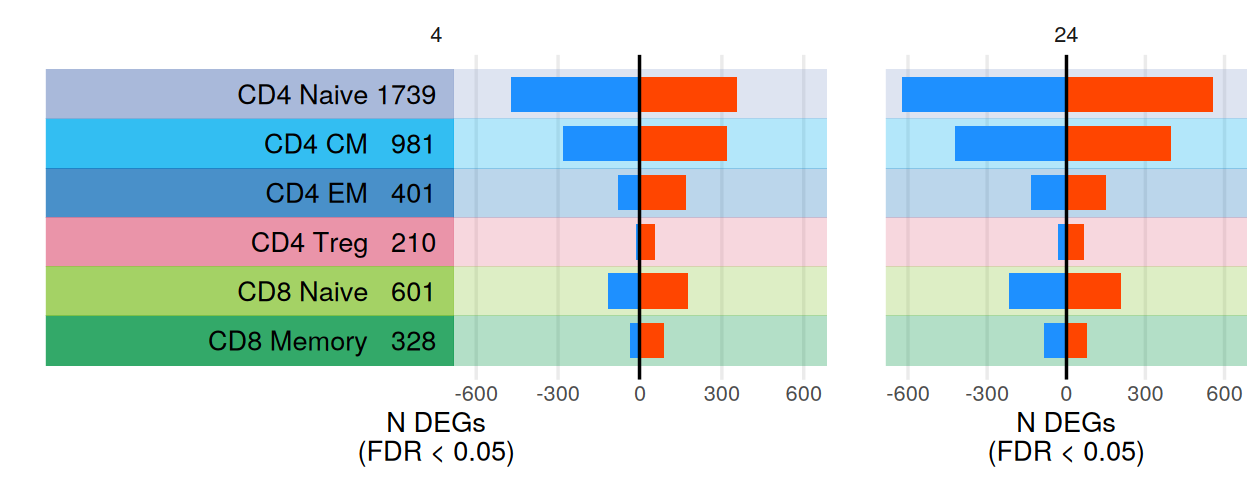

In [25]:
options(repr.plot.width = 10.5, repr.plot.height = 4)
all_plots <- plot_grid(
    plotlist = treat_plots,
    nrow = 1, ncol = 2,
    rel_widths = c(2,1)
)
all_plots

In [26]:
out_file <- file.path(
    out_dir,
    paste0("dexamethasone_deg_barplot_",Sys.Date(),".pdf")
)
ggsave(out_file,
       all_plots,
       width = 10.5, height = 4)

### DAP Barplots

In [27]:
fdr_cutoff <- 0.05

In [28]:
all_dap <- read.csv(dap_file)

In [29]:
head(all_dap)

,aifi_cell_type,fg,bg,seqnames,start,end,logFC,adjP,MeanDiff,idx
,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>
1,t_cd4_cm,bortezomib_4,dmso_4,chr1,817097,817597,0.76247158,0.9617006,0.016549055,1
2,t_cd4_cm,bortezomib_4,dmso_4,chr1,827316,827816,-0.01214597,0.9617006,-0.002062272,2
3,t_cd4_cm,bortezomib_4,dmso_4,chr1,844402,844902,-0.72051897,0.9617006,-0.017751078,3
4,t_cd4_cm,bortezomib_4,dmso_4,chr1,903980,904480,-1.17605733,0.9617006,-0.016888331,6
5,t_cd4_cm,bortezomib_4,dmso_4,chr1,904495,904995,-0.21563641,0.9617006,-0.040113108,7
6,t_cd4_cm,bortezomib_4,dmso_4,chr1,942207,942707,-0.89654326,0.9617006,-0.042661663,16


In [30]:
all_dap <- all_dap %>%
  mutate(timepoint = sub(".+_","",fg),
         fg = sub("_.+","",fg),
         bg = sub("_.+","",bg)) %>%
  filter(fg == "dexamethasone") %>%
  mutate(direction = ifelse(logFC > 0, "up", "dn"))

In [31]:
head(all_dap)

,aifi_cell_type,fg,bg,seqnames,start,end,logFC,adjP,MeanDiff,idx,timepoint,direction
,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>,<chr>,<chr>
1,t_cd4_cm,dexamethasone,dmso,chr6,42045644,42046144,2.421212,3.335283e-19,0.5512348,1967,4,up
2,t_cd4_cm,dexamethasone,dmso,chr10,72248667,72249167,2.229108,1.104087e-14,0.4514588,1686,4,up
3,t_cd4_cm,dexamethasone,dmso,chr2,43131177,43131677,1.445011,1.489657e-14,0.6459661,1046,4,up
4,t_cd4_cm,dexamethasone,dmso,chr20,36930568,36931068,3.188709,1.489657e-14,0.3657697,903,4,up
5,t_cd4_cm,dexamethasone,dmso,chr3,56787791,56788291,3.429534,5.897401e-11,0.2886989,1651,4,up
6,t_cd4_cm,dexamethasone,dmso,chr18,13438096,13438596,2.047361,1.402481e-10,0.2475590,304,4,up


In [32]:
table(all_dap$aifi_cell_type)


    t_cd4_cm     t_cd4_em  t_cd4_naive   t_cd4_treg t_cd8_memory  t_cd8_naive 
      145013       142175       134745       117030       136169       145192 

In [33]:
dap_summary <- all_dap %>%
  group_by(fg, timepoint, aifi_cell_type) %>%
  summarise(n_sig = sum(adjP < fdr_cutoff),
            n_up = sum(adjP < fdr_cutoff & direction == "up"),
            n_dn = sum(adjP < fdr_cutoff & direction == "dn"),
            .groups = "keep")

In [34]:
head(dap_summary)

fg,timepoint,aifi_cell_type,n_sig,n_up,n_dn
<chr>,<chr>,<chr>,<int>,<int>,<int>
dexamethasone,24,t_cd4_cm,443,302,141
dexamethasone,24,t_cd4_em,72,54,18
dexamethasone,24,t_cd4_naive,260,138,122
dexamethasone,24,t_cd4_treg,4,4,0
dexamethasone,24,t_cd8_memory,28,26,2
dexamethasone,24,t_cd8_naive,136,101,35


In [35]:
plot_data <- dap_summary %>%
  left_join(type_colors) %>%
  mutate(treat_time = paste0(fg,"_",timepoint)) %>%
  group_by(fg) %>%
  mutate(max_val = max(c(n_up, n_dn))) %>%
  ungroup()

Joining with `by = join_by(aifi_cell_type)`


In [36]:
plot_data %>%
  filter(fg == "dexamethasone",
         aifi_cell_type == "t_cd4_naive")

fg,timepoint,aifi_cell_type,n_sig,n_up,n_dn,cell_type_label,cell_type_color,cell_type_xpos,cell_type_ypos,treat_time,max_val
<chr>,<chr>,<chr>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<int>
dexamethasone,24,t_cd4_naive,260,138,122,CD4 Naive,#93A7D1,1,7,dexamethasone_24,302
dexamethasone,4,t_cd4_naive,99,95,4,CD4 Naive,#93A7D1,1,7,dexamethasone_4,302


In [37]:
write.csv(
    plot_data,
    file.path(out_dir, paste0("dexamethasone_dap_summary_data_", Sys.Date(), ".csv")),
    quote = FALSE,
    row.names = FALSE
)

In [38]:
treat_times <- paste0("dexamethasone_", c(4, 24))

In [39]:
treat_plots <- map(
    treat_times,
    function(tt) {
        
        pd <- plot_data %>%
          filter(treat_time == tt)
        
        x_max <- pd$max_val[1]
        x_min <- -1 * x_max
        x_breaks <- unique(c(seq(signif(x_min, 1), 0, length.out = 3),
                             seq(0, signif(x_max, 1), length.out = 3)))
        x_max <- max(x_max, x_breaks[length(x_breaks)])
        x_min <- min(x_min, x_breaks[1])
        
        timepoint <- pd$timepoint[1]

        up_pd <- pd %>%
          mutate(xmin = 0, xmax = n_up,
                 fill = "orangered")
        dn_pd <- pd %>%
          mutate(xmin = -1 * n_dn, xmax = 0,
                 fill = "dodgerblue")
        
        pd <- rbind(up_pd, dn_pd)
        
        plot_ypos <- pd %>%
          select(aifi_cell_type, cell_type_label, 
                 cell_type_color, cell_type_ypos, 
                 n_sig) %>%
          unique()
        
        p <- ggplot()
        
        if(timepoint == 4) {
            x_lim <- c(x_min * 3.5, x_max * 1.1)
            
            p <- p + geom_rect(data = plot_ypos,
                    aes(ymin = cell_type_ypos - 0.5, ymax = cell_type_ypos + 0.5,
                        xmin = x_min * 3.5, xmax = x_min * 1.1,
                        fill = cell_type_color),
                    alpha = 0.8) +
            geom_text(data = plot_ypos,
                    aes(x = x_min * 1.6, y = cell_type_ypos,
                        label = cell_type_label),
                    hjust = 1,
                    vjust = 0.5)
            
        } else {
            x_lim <- c(x_min * 1.1, x_max * 1.1)
        }
        p <- p +
          geom_rect(data = plot_ypos,
                    aes(ymin = cell_type_ypos - 0.5, ymax = cell_type_ypos + 0.5,
                        xmin = x_min * 1.1, xmax = x_max * 1.1,
                        fill = cell_type_color),
                    alpha = 0.3) +
          geom_rect(data = pd,
                   aes(ymin = cell_type_ypos - 0.35, ymax = cell_type_ypos + 0.35,
                       xmin = xmin, xmax = xmax,
                       fill = fill)) +
          geom_vline(data = data.frame(x = 0),
                     aes(xintercept = x)) +
          scale_y_continuous("",
                             limits = c(min(plot_ypos$cell_type_ypos) - 0.5, max(plot_ypos$cell_type_ypos) + 0.5)) +
          scale_fill_identity() +
          scale_x_continuous(paste0("N DAPs\n(FDR < ",fdr_cutoff,")"),
                             limits = x_lim,
                             breaks = x_breaks,
                             expand = c(0,0)) +
          theme_bw(base_size = 16) +
          facet_wrap(~ timepoint, ncol = 3) +
          theme(panel.grid.major.y = element_blank(),
                panel.grid.minor = element_blank(),
                axis.ticks = element_blank(),
                axis.text.y = element_blank(),
                panel.border = element_blank(),
                strip.background = element_blank())
        
        p
    }
)
names(treat_plots) <- treat_times

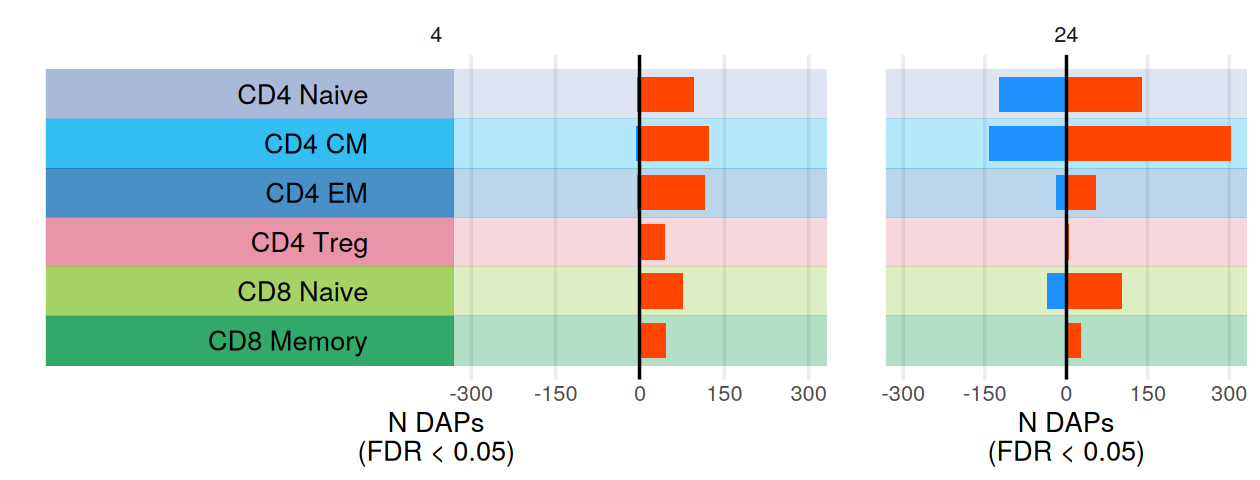

In [40]:
options(repr.plot.width = 10.5, repr.plot.height = 4)
all_plots <- plot_grid(
    plotlist = treat_plots,
    nrow = 1, ncol = 2,
    rel_widths = c(2,1)
)
all_plots

In [41]:
out_file <- file.path(
    out_dir,
    paste0("dexamethasone_dap_barplot_",Sys.Date(),".pdf")
)
ggsave(out_file,
       all_plots,
       width = 10.5, height = 4)

### DDE Barplots
Differentially detected epitopes, aka Differentially expressed proteins (DEP)

In [42]:
fdr_cutoff <- 0.05

In [43]:
all_dep <- read.csv(dep_file)

In [44]:
all_dep <- all_dep %>%
  filter(fg == "dexamethasone") %>%
  mutate(direction = ifelse(logFC > 0, "up", "dn"))

In [45]:
dep_epitope_summary <- all_dep %>%
  filter(adjP < fdr_cutoff) %>%
  group_by(fg, feature, direction) %>%
  summarise(n_types_up = n(), .groups = "keep")

In [46]:
dep_summary <- all_dep %>%
  group_by(fg, timepoint, aifi_cell_type) %>%
  summarise(n_sig = sum(adjP < fdr_cutoff),
            n_up = sum(adjP < fdr_cutoff & direction == "up"),
            n_dn = sum(adjP < fdr_cutoff & direction == "dn"),
            .groups = "keep")

In [47]:
plot_data <- dep_summary %>%
  left_join(type_colors) %>%
  mutate(treat_time = paste0(fg,"_",timepoint)) %>%
  group_by(fg) %>%
  mutate(max_val = max(c(n_up, n_dn))) %>%
  ungroup()

Joining with `by = join_by(aifi_cell_type)`


In [48]:
plot_data %>%
  filter(fg == "dexamethasone",
         aifi_cell_type == "t_cd4_naive")

fg,timepoint,aifi_cell_type,n_sig,n_up,n_dn,cell_type_label,cell_type_color,cell_type_xpos,cell_type_ypos,treat_time,max_val
<chr>,<int>,<chr>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<int>
dexamethasone,4,t_cd4_naive,5,2,3,CD4 Naive,#93A7D1,1,7,dexamethasone_4,10
dexamethasone,24,t_cd4_naive,10,4,6,CD4 Naive,#93A7D1,1,7,dexamethasone_24,10


In [49]:
write.csv(
    plot_data,
    file.path(out_dir, paste0("dexamethasone_dde_summary_data_", Sys.Date(), ".csv")),
    quote = FALSE,
    row.names = FALSE
)

In [50]:
treat_times <- paste0("dexamethasone_", c(4, 24))

In [51]:
treat_plots <- map(
    treat_times,
    function(tt) {
        
        pd <- plot_data %>%
          filter(treat_time == tt)
        
        x_max <- pd$max_val[1]
        x_min <- -1 * x_max
        x_breaks <- unique(c(seq(signif(x_min, 1), 0, length.out = 3),
                             seq(0, signif(x_max, 1), length.out = 3)))
        
        timepoint <- pd$timepoint[1]
        
        up_pd <- pd %>%
          mutate(xmin = 0, xmax = n_up,
                 fill = "orangered")
        dn_pd <- pd %>%
          mutate(xmin = -1 * n_dn, xmax = 0,
                 fill = "dodgerblue")
        
        pd <- rbind(up_pd, dn_pd)
        
        plot_ypos <- pd %>%
          select(aifi_cell_type, cell_type_label, 
                 cell_type_color, cell_type_ypos, 
                 n_sig) %>%
          unique()
        
        p <- ggplot()
        
        if(timepoint == 4) {
            x_lim <- c(x_min * 3.5, x_max * 1.1)
            
            p <- p + geom_rect(data = plot_ypos,
                    aes(ymin = cell_type_ypos - 0.5, ymax = cell_type_ypos + 0.5,
                        xmin = x_min * 3.5, xmax = x_min * 1.1,
                        fill = cell_type_color),
                    alpha = 0.8) +
            geom_text(data = plot_ypos,
                    aes(x = x_min * 1.6, y = cell_type_ypos,
                        label = cell_type_label),
                    hjust = 1,
                    vjust = 0.5)
            
        } else {
            x_lim <- c(x_min * 1.1, x_max * 1.1)
        }
        p <- p +
          geom_rect(data = plot_ypos,
                    aes(ymin = cell_type_ypos - 0.5, ymax = cell_type_ypos + 0.5,
                        xmin = x_min * 1.1, xmax = x_max * 1.1,
                        fill = cell_type_color),
                    alpha = 0.3) +
          geom_rect(data = pd,
                   aes(ymin = cell_type_ypos - 0.35, ymax = cell_type_ypos + 0.35,
                       xmin = xmin, xmax = xmax,
                       fill = fill)) +
          geom_vline(data = data.frame(x = 0),
                     aes(xintercept = x)) +
          scale_y_continuous("",
                             limits = c(min(plot_ypos$cell_type_ypos) - 0.5, max(plot_ypos$cell_type_ypos) + 0.5)) +
          scale_fill_identity() +
          scale_x_continuous(paste0("N DDEs\n(FDR < ",fdr_cutoff,")"),
                             limits = x_lim,
                             breaks = x_breaks,
                             expand = c(0,0)) +
          theme_bw(base_size = 16) +
          facet_wrap(~ timepoint, ncol = 3) +
          theme(panel.grid.major.y = element_blank(),
                panel.grid.minor = element_blank(),
                axis.ticks = element_blank(),
                axis.text.y = element_blank(),
                panel.border = element_blank(),
                strip.background = element_blank())
        
        p
    }
)
names(treat_plots) <- treat_times

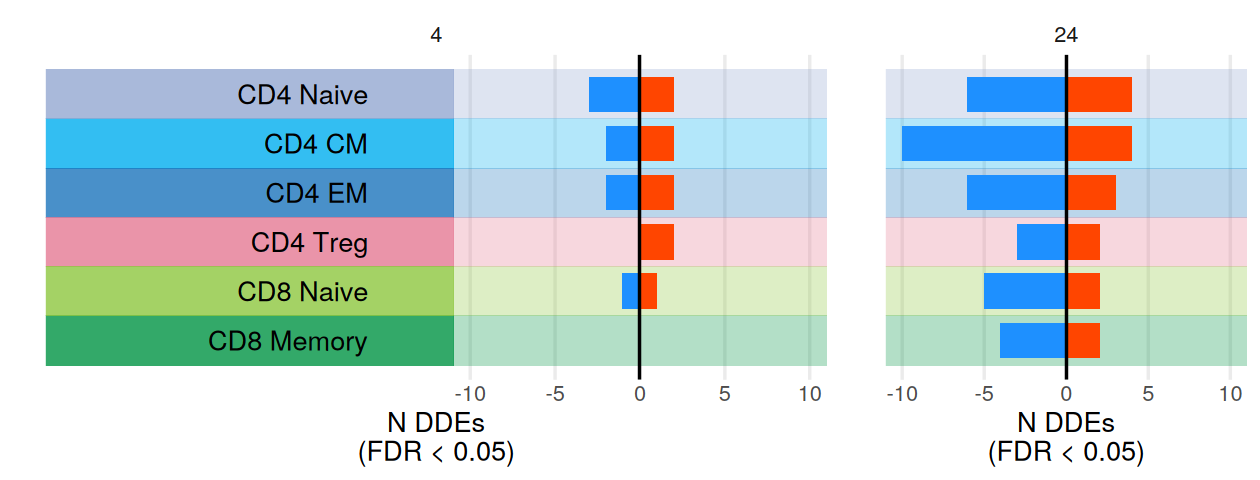

In [52]:
options(repr.plot.width = 10.5, repr.plot.height = 4)
all_plots <- plot_grid(
    plotlist = treat_plots,
    nrow = 1, ncol = 2,
    rel_widths = c(2,1)
)
all_plots

In [53]:
out_file <- file.path(
    out_dir,
    paste0("dexamethasone_dde_barplot_",Sys.Date(),".pdf")
)
ggsave(out_file,
       all_plots,
       width = 10.5, height = 4)

## Hallmark pathway enrichment heatmaps

In [54]:
fdr_cutoff <- 0.05

In [55]:
hallmark_names <- read.csv("../common/gene_sets/hallmark_names.csv")

In [56]:
type_colors <- read.csv("../common/color_sets/aifi_cell_type_colors.csv")

Gradient colors

In [57]:
lo_gc <- data.frame(NES = seq(-3, -1.01, 0.01)) %>%
  mutate(nes_color = colorRampPalette(c("darkblue", "skyblue"))(n()))
mid_lo_gc <- data.frame(NES = seq(-1, 0, 0.01), nes_color = "gray80")
hi_gc <- data.frame(NES = seq(3,1.01,-0.01)) %>%
  mutate(nes_color = colorRampPalette(c("darkred", "coral"))(n()))
mid_hi_gc <- data.frame(NES = seq(1, 0.01, -0.01), nes_color = "gray80")

gc_df <- do.call(rbind, list(lo_gc, mid_lo_gc, mid_hi_gc, hi_gc))
gc_df$NES <- as.character(gc_df$NES)

In [58]:
all_hallmark <- read.csv(hallmark_file)

In [59]:
all_hallmark <- all_hallmark %>%
  filter(fg == "dexamethasone")

In [60]:
head(all_hallmark)

,fg,bg,timepoint,aifi_cell_type,pathway_label,NES,nomP,adjP,n_leadingEdge,n_pathway_genes,leadingEdge,pathway_genes
,<chr>,<chr>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<int>,<int>,<chr>,<chr>
1,dexamethasone,dmso,24,t_cd4_cm,PI3K/AKT/mTOR Signaling,1.701149,0.009566838,0.1822074,76,118,CXCR4;SLA;VAV3;PTEN,ACACA;ACACA;ACTR2;ACTR3;ADCY2;AKT1;AKT1S1;AP2M1;ARF1;ARHGDIA;ARPC3;ATF1;CAB39;CAB39L;CALR;CAMK4;CDK1;CDK2;CDK4;CDKN1A;CDKN1B;CFL1;CLTC;CSNK2B;CSNK2B;CSNK2B;CSNK2B;CSNK2B;CSNK2B;CSNK2B;CSNK2B;CXCR4;DAPP1;DDIT3;DUSP3;E2F1;ECSIT;EGFR;EIF4E;FASLG;FGF17;FGF22;FGF6;GNA14;GNGT1;GRB2;GRK2;GSK3B;HRAS;HRAS;HSP90B1;IL2RG;IL4;IRAK4;ITPR2;LCK;MAP2K3;MAP2K6;MAP3K7;MAPK1;MAPK10;MAPK8;MAPK9;MAPKAP1;MKNK1;MKNK2;MYD88;NCK1;NFKBIB;NFKBIB;NGF;NOD1;PAK4;PDK1;PFN1;PIK3R3;PIKFYVE;PIN1;PITX2;PLA2G12A;PLCB1;PLCG1;PPP1CA;PPP2R1B;PRKAA2;PRKAG1;PRKAR2A;PRKCB;PTEN;PTEN;PTPN11;RAC1;RAF1;RALB;RIPK1;RIT1;RPS6KA1;RPS6KA1;RPS6KA3;RPTOR;SFN;SLA;SLC2A1;SMAD2;SQSTM1;SQSTM1;STAT2;TBK1;THEM4;TIAM1;TNFRSF1A;TRAF2;TRIB3;TSC2;UBE2D3;UBE2N;VAV3;YWHAB
2,dexamethasone,dmso,24,t_cd4_cm,P53 Pathway,1.689426,0.008070706,0.1822074,107,215,TXNIP;CCND3;ZBTB16;BTG1;DDIT4;SOCS1;KIF13B;FOXO3;TSPYL2;RNF19B;UPP1;SP1;RB1;ZFP36L1,ABAT;ABCC5;ABHD4;ACVR1B;ADA;AEN;AK1;ALOX15B;ANKRA2;APAF1;APP;ATF3;BAIAP2;BAK1;BAX;BLCAP;BMP2;BTG1;BTG2;CASP1;CCND2;CCND3;CCNG1;CCNK;CCP110;CD81;CD82;CDH13;CDK5R1;CDKN1A;CDKN2A;CDKN2AIP;CDKN2B;CEBPA;CGRRF1;CLCA2;COQ8A;CSRNP2;CTSD;CTSF;CYFIP2;DCXR;DDB2;DDIT3;DDIT4;DEF6;DGKA;DNTTIP2;DRAM1;EI24;ELP1;EPHA2;EPHX1;EPS8L2;ERCC5;F2R;FAM162A;FAS;FBXW7;FDXR;FGF13;FOS;FOXO3;FUCA1;GADD45A;GLS2;GM2A;GPX2;H1-2;H2AJ;H2AW;H2AW;HBEGF;HDAC3;HEXIM1;HINT1;HMOX1;HRAS;HRAS;HSPA4L;IER3;IER3;IER3;IER3;IER3;IER3;IER3;IER5;IFI30;IL1A;INHBB;IP6K2;IRAG2;IRAK1;ISCU;ITGB4;JAG2;JUN;KIF13B;KLF4;KLK8;KRT17;LDHB;LIF;MAPKAPK3;MDM2;MKNK2;MXD1;MXD4;NDRG1;NHLH2;NINJ1;NOL8;NOTCH1;NUDT15;NUPR1;OSGIN1;PCNA;PDGFA;PERP;PHLDA3;PIDD1;PITPNC1;PLK2;PLK3;PLXNB2;PMM1;POLH;POM121;PPM1D;PPP1R15A;PRKAB1;PRMT2;PROCR;PTPN14;PTPRE;PVT1;RAB40C;RACK1;RAD51C;RAD9A;RALGDS;RAP2B;RB1;RCHY1;RETSAT;RGS16;RHBDF2;RNF19B;RPL18;RPL36;RPS12;RPS27L;RRAD;RRP8;RXRA;S100A10;S100A4;SAT1;SDC1;SEC61A1;SERPINB5;SERTAD3;SESN1;SFN;SLC19A2;SLC35D1;SLC3A2;SLC7A11;SOCS1;SP1;SPHK1;ST14;STEAP3;STOM;TAP1;TAP1;TAP1;TAP1;TAP1;TAP1;TAP1;TAP1;TAX1BP3;TCHH;TCN2;TGFA;TGFB1;TM4SF1;TM7SF3;TNFSF9;TNNI1;TOB1;TP53;TP63;TPD52L1;TPRKB;TRAF4;TRAFD1;TRIAP1;TRIB3;TSC22D1;TSPYL2;TXNIP;UPP1;VAMP8;VDR;VWA5A;WRAP73;WWP1;XPC;ZBTB16;ZFP36L1;ZMAT3;ZNF365
3,dexamethasone,dmso,24,t_cd4_cm,Hypoxia,1.641908,0.016449652,0.1822074,91,215,CXCR4;BCL2;BTG1;ETS1;UGP2;KLF7;DDIT4;MYH9;FOXO3;KLHL24;KDM3A,ACKR3;ADM;ADORA2B;AK4;AKAP12;ALDOA;ALDOB;ALDOC;AMPD3;ANGPTL4;ANKZF1;ANXA2;ATF3;ATP7A;B3GALT6;B4GALNT2;BCAN;BCL2;BGN;BHLHE40;BNIP3L;BRS3;BTG1;CA12;CASP6;CAV1;CAVIN1;CAVIN3;CCN1;CCN2;CCN5;CCNG2;CDKN1A;CDKN1B;CDKN1C;CDKN1C;CHST2;CHST3;CITED2;COL5A1;CP;CSRP2;CXCR4;DCN;DDIT3;DDIT4;DPYSL4;DTNA;DUSP1;EDN2;EFNA1;EFNA3;EGFR;ENO1;ENO2;ENO3;ERO1A;ERRFI1;ETS1;EXT1;F3;FAM162A;FBP1;FOS;FOSL2;FOXO3;GAA;GALK1;GAPDH;GAPDHS;GBE1;GCK;GCNT2;GCNT2;GLRX;GPC1;GPC3;GPC4;GPI;GPI;GRHPR;GYS1;HAS1;HDLBP;HEXA;HK1;HK2;HMOX1;HOXB9;HS3ST1;HSPA5;IDS;IER3;IER3;IER3;IER3;IER3;IER3;IER3;IGFBP1;IGFBP3;IL6;ILVBL;INHA;IRS2;ISG20;JMJD6;JUN;KDELR3;KDM3A;KIF5A;KLF6;KLF7;KLHL24;LALBA;LARGE1;LDHA;LDHA;LDHC;LOX;LXN;MAFF;MAP3K1;MIF;MIF;MT1E;MT2A;MXI1;MYH9;NAGK;NCAN;NDRG1;NDST1;NDST2;NEDD4L;NFIL3;NOCT;NR3C1;P4HA1;P4HA2;PAM;PCK1;PDGFB;PDK1;PDK3;PFKFB3;PFKL;PFKP;PGAM2;PGF;PGK1;PGM1;PGM2;PHKG1;PIM1;PKLR;PKLR;PKP1;PLAC8;PLAUR;PLIN2;PNRC1;PPARGC1A;PPFIA4;PPP1R15A;PPP1R3C;PRDX5;PRKCA;PYGM;RBPJ;RORA;RRAGD;S100A4;SAP30;SCARB1;SDC2;SDC3;SDC4;SELENBP1;SERPINE1;SIAH2;SLC25A1;SLC2A1;SLC2A3;SLC2A5;SLC37A4;SLC37A4;SLC37A4;SLC6A6;SRPX;STBD1;STC1;STC2;SULT2B1;TES;TGFB3;TGFBI;TGM2;TIPARP;TKTL1;TMEM45A;TNFAIP3;TPBG;TPBG;TPD52;TPI1;TPST2;UGP2;VEGFA;VHL;VLDLR;WSB1;XPNPEP1;ZFP36;ZNF292
4,dexamethasone,dmso,24,t_cd4_cm,Estrogen Response Early,1.601981,0.041322314,0.2345059,75,216,FKBP5;BCL2;MAST4;UGCG;IL6ST;MYB;XBP1,ABAT;ABCA3;ABHD2;ABLIM1;ADCY1;

Add treat_time, display labels for pathways, and cell type 

In [61]:
plot_hallmark <- all_hallmark %>%
  mutate(label_time = ifelse(timepoint == 4, "04", as.character(timepoint))) %>%
  mutate(treat_time = paste0(fg, "_", label_time)) %>%
  left_join(hallmark_names) %>%
  left_join(type_colors)

Joining with `by = join_by(pathway_label)`
Joining with `by = join_by(aifi_cell_type)`


In [62]:
top_n <- 20

sig_data <- plot_hallmark %>%
  filter(adjP < fdr_cutoff) %>%
  group_by(pathway) %>%
  arrange(adjP) %>%
  slice(1) %>%
  ungroup() %>%
  arrange(adjP) %>%
  head(top_n)

plot_data <- plot_hallmark %>%
  filter(pathway %in% sig_data$pathway)

xpos_df <- plot_data %>%
  select(cell_type_label, cell_type_xpos) %>%
  unique() %>%
  arrange(cell_type_xpos) %>%
  mutate(xpos = 1:n())

ypos_df <- plot_data %>%
  select(pathway_label) %>%
  unique() %>%
  arrange(pathway_label) %>%
  mutate(ypos = n():1)

timepoint_df <- data.frame(
    timepoint = c(4, 24),
    timepoint_label = factor(c("Dexamethasone, 4 Hours", "Dexamethasone, 24 Hours"), 
                             levels = c("Dexamethasone, 4 Hours", "Dexamethasone, 24 Hours"))
)

plot_data <- plot_data %>%
  left_join(xpos_df) %>%
  left_join(ypos_df) %>%
  mutate(NES = as.character(round(NES, 2))) %>%
  left_join(gc_df) %>%
  left_join(timepoint_df)

Joining with `by = join_by(cell_type_label, cell_type_xpos)`
Joining with `by = join_by(pathway_label)`
Joining with `by = join_by(NES)`
Joining with `by = join_by(timepoint)`


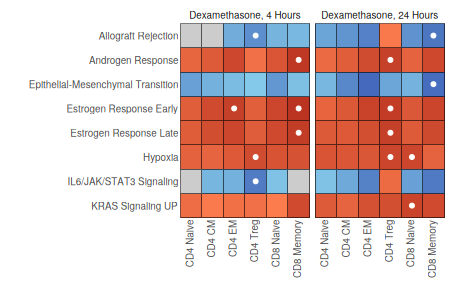

In [63]:
options(repr.plot.width = 3.75, repr.plot.height = 2.5)
hallmark_plot <- ggplot() +
  geom_tile(
      data = plot_data,
      aes(x = xpos,
          y = ypos,
          fill = nes_color),
      color = "black") +
  geom_point(
      data = plot_data %>% filter(adjP < fdr_cutoff),
      aes(x = xpos,
          y = ypos),
      color = "white",
      size = 0.9) +
  scale_fill_identity() +
  scale_x_continuous(
      "",
      breaks = xpos_df$xpos,
      labels = xpos_df$cell_type_label,
      expand = c(0, 0)) +
  scale_y_continuous(
      "",
      breaks = ypos_df$ypos,
      labels = ypos_df$pathway_label,
      expand = c(0, 0)) +
  facet_wrap(~ timepoint_label) +
  theme_bw(base_size = 7) +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.3),
        panel.border = element_blank(),
        axis.ticks = element_blank(),
        strip.background = element_blank(),
        panel.grid = element_blank(),
        panel.background = element_rect(fill = "gray30"))
hallmark_plot

In [64]:
out_file <- file.path(
    out_dir,
    paste0("dexamethasone_hallmark_heatmap_",Sys.Date(),".pdf")
)
ggsave(out_file,
       hallmark_plot,
       width = 3.75, height = 2.5)

## Motif enrichment volcano plots

Select columns from DEG results to highlight TFs that are differentially expressed by color in the volcano plots

In [65]:
sel_deg <- all_deg %>%
  select(aifi_cell_type, timepoint, fg, bg, gene, adjP, logFC, direction) %>%
  rename(tf_gene = gene,
         tf_adjP = adjP,
         tf_logFC = logFC,
         tf_direction = direction) 

Read the motif enrichment results

In [66]:
all_dem <- read.csv(dem_file)

In [67]:
all_dem <- all_dem %>%
  mutate(timepoint = as.numeric(sub(".+_","",fg)),
         fg = sub("_.+","",fg),
         bg = sub("_.+","",bg)) %>%
  filter(fg == "dexamethasone") %>%
  left_join(sel_deg)

Joining with `by = join_by(aifi_cell_type, fg, bg, tf_gene, timepoint)`


Filter for expressed TFs, which will have tf_adjP, tf_logFC, and tf_direction joined from the DEG results

In [68]:
all_dem <- all_dem %>%
  filter(!is.na(tf_direction))

Convert Enrichment for motifs enriched near down-regulated genes to negative values

In [69]:
all_dem <- all_dem %>%
  mutate(Enrichment = ifelse(
      direction == "dn",
      -1 * Enrichment,
      Enrichment))

Add cell type labels and ordering

In [70]:
all_dem <- all_dem %>%
  left_join(type_colors) %>%
  mutate(cell_type_label = factor(cell_type_label, levels = type_colors$cell_type_label))

Joining with `by = join_by(aifi_cell_type)`


### 4 hr

In [71]:
plot_dem <- all_dem %>%
  filter(timepoint == 4) %>%
  mutate(color = case_when(
      tf_adjP < 0.05 & tf_direction == "up" ~ "orangered",
      tf_adjP < 0.05 & tf_direction == "dn" ~ "dodgerblue",
      TRUE ~ "gray60",
  ))

In [72]:
write.csv(
    plot_dem,
    file.path(out_dir, paste0("dexamethasone_4hr_dem_data_", Sys.Date(), ".csv")),
    quote = FALSE,
    row.names = FALSE
)

In [73]:
max_enrich <- max(plot_dem$Enrichment)
max_mlp <- max(plot_dem$mlog10Padj)

In [74]:
label_top_n <- 8

up_label_dem <- plot_dem %>%
  filter(adjP < 0.05,
         direction == "up") %>%
  group_by(aifi_cell_type) %>%
  arrange(adjP) %>%
  filter(1:n() <= label_top_n) %>%
  mutate(ypos = seq(max_mlp * 0.85, max_mlp * 0.15, length.out = n()),
         xpos = max_enrich * 1.1) %>%
  ungroup()

dn_label_dem <- plot_dem %>%
  filter(adjP < 0.05,
         direction == "dn") %>%
  group_by(aifi_cell_type) %>%
  arrange(adjP) %>%
  filter(1:n() <= label_top_n) %>%
  mutate(ypos = seq(max_mlp * 0.85, max_mlp * 0.15, length.out = n()),
         xpos = -1 * max_enrich * 1.1) %>%
  ungroup()

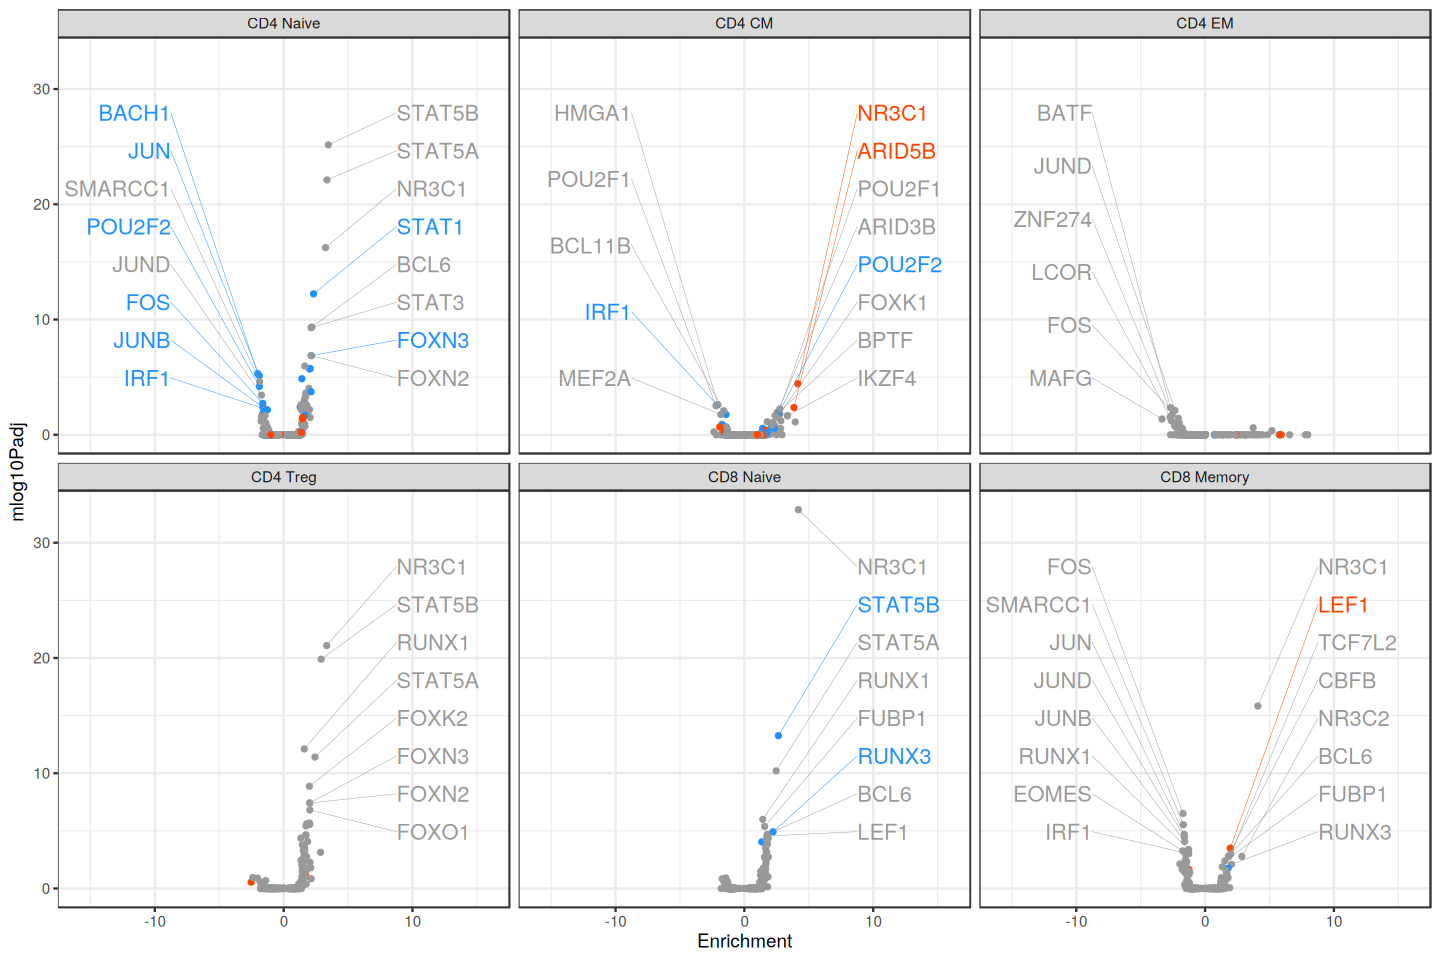

In [75]:
options(repr.plot.width = 12, repr.plot.height = 8)

volcano_plots <- ggplot() +
  geom_point(
      data = plot_dem,
      aes(x = Enrichment,
          y = mlog10Padj,
          color = color),
      size = 1
  ) +
  geom_segment(
      data = up_label_dem,
      aes(x = xpos, xend = Enrichment,
          y = ypos, yend = mlog10Padj,
          color = color),
      linewidth = 0.1
  ) +
  geom_text(
      data = up_label_dem,
      aes(x = xpos,
          y = ypos,
          color = color,
          label = tf_gene),
      size = 4.5,
      hjust = 0
  ) +
  geom_segment(
      data = dn_label_dem,
      aes(x = xpos, xend = Enrichment,
          y = ypos, yend = mlog10Padj,
          color = color),
      linewidth = 0.1
  ) +
  geom_text(
      data = dn_label_dem,
      aes(x = xpos,
          y = ypos,
          color = color,
          label = tf_gene),
      size = 4.5,
      hjust = 1
  ) +
  scale_color_identity() +
  scale_x_continuous(
      limits = c(-2 * max_enrich, 2 * max_enrich)
  ) +
  facet_wrap(
      ~ cell_type_label,
      ncol = 3,
      nrow = 2
  ) +
  theme_bw()

volcano_plots

In [76]:
out_file <- file.path(
    out_dir,
    paste0("dexamethasone_4hr_dem_volcano_plots_",Sys.Date(),".pdf")
)
ggsave(out_file,
       volcano_plots,
       width = 12, height = 8)

### 24 hr

In [77]:
plot_dem <- all_dem %>%
  filter(timepoint == 24) %>%
  mutate(color = case_when(
      tf_adjP < 0.05 & tf_direction == "up" ~ "orangered",
      tf_adjP < 0.05 & tf_direction == "dn" ~ "dodgerblue",
      TRUE ~ "gray60",
  ))

In [78]:
write.csv(
    plot_dem,
    file.path(out_dir, paste0("dexamethasone_24hr_dem_data_", Sys.Date(), ".csv")),
    quote = FALSE,
    row.names = FALSE
)

In [79]:
max_enrich <- max(plot_dem$Enrichment)
max_mlp <- max(plot_dem$mlog10Padj)

In [80]:
label_top_n <- 8

up_label_dem <- plot_dem %>%
  filter(adjP < 0.05,
         direction == "up") %>%
  group_by(aifi_cell_type) %>%
  arrange(adjP) %>%
  filter(1:n() <= label_top_n) %>%
  mutate(ypos = seq(max_mlp * 0.85, max_mlp * 0.15, length.out = n()),
         xpos = max_enrich * 1.1) %>%
  ungroup()

dn_label_dem <- plot_dem %>%
  filter(adjP < 0.05,
         direction == "dn") %>%
  group_by(aifi_cell_type) %>%
  arrange(adjP) %>%
  filter(1:n() <= label_top_n) %>%
  mutate(ypos = seq(max_mlp * 0.85, max_mlp * 0.15, length.out = n()),
         xpos = -1 * max_enrich * 1.1) %>%
  ungroup()

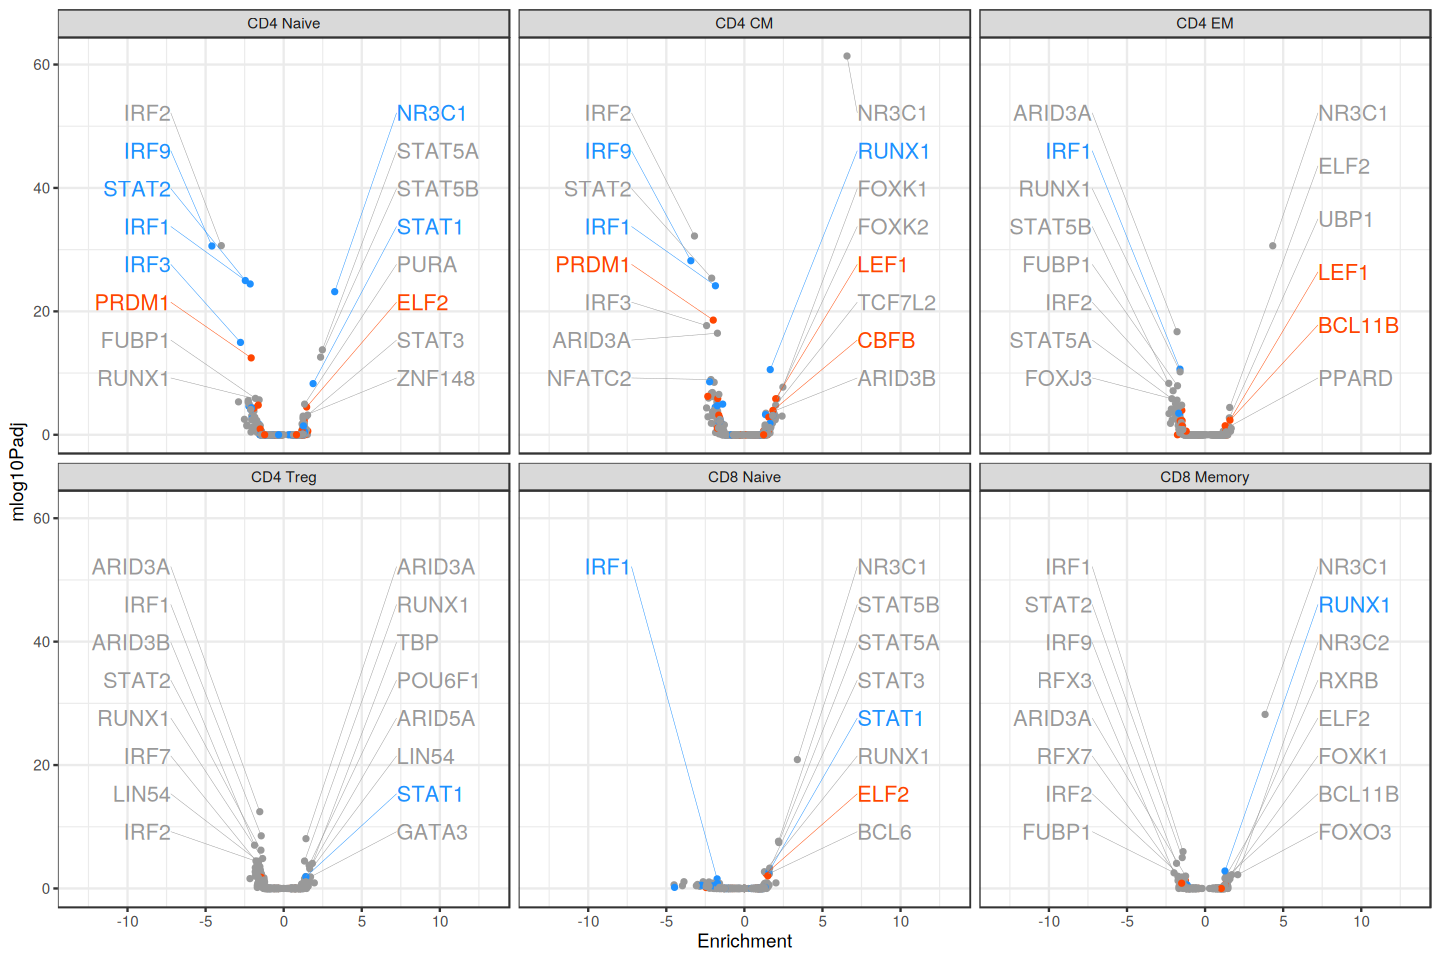

In [81]:
options(repr.plot.width = 12, repr.plot.height = 8)

volcano_plots <- ggplot() +
  geom_point(
      data = plot_dem,
      aes(x = Enrichment,
          y = mlog10Padj,
          color = color),
      size = 1
  ) +
  geom_segment(
      data = up_label_dem,
      aes(x = xpos, xend = Enrichment,
          y = ypos, yend = mlog10Padj,
          color = color),
      linewidth = 0.1
  ) +
  geom_text(
      data = up_label_dem,
      aes(x = xpos,
          y = ypos,
          color = color,
          label = tf_gene),
      size = 4.5,
      hjust = 0
  ) +
  geom_segment(
      data = dn_label_dem,
      aes(x = xpos, xend = Enrichment,
          y = ypos, yend = mlog10Padj,
          color = color),
      linewidth = 0.1
  ) +
  geom_text(
      data = dn_label_dem,
      aes(x = xpos,
          y = ypos,
          color = color,
          label = tf_gene),
      size = 4.5,
      hjust = 1
  ) +
  scale_color_identity() +
  scale_x_continuous(
      limits = c(-2 * max_enrich, 2 * max_enrich)
  ) +
  facet_wrap(
      ~ cell_type_label,
      ncol = 3,
      nrow = 2
  ) +
  theme_bw()

volcano_plots

In [82]:
out_file <- file.path(
    out_dir,
    paste0("dexamethasone_24hr_dem_volcano_plots_",Sys.Date(),".pdf")
)
ggsave(out_file,
       volcano_plots,
       width = 12, height = 8)

# Store results in HISE

Finally, we store the output file in our Collaboration Space for later retrieval and use. We need to provide the UUID for our Collaboration Space (aka `studySpaceId`), as well as a title for this step in our analysis process.

The hise function `uploadFiles()` also requires the FileIDs from the original fileset for reference.

In [83]:
study_space_uuid <- "40df6403-29f0-4b45-ab7d-f46d420c422e"
title <- paste("VRd TEA-seq Figure 5", Sys.Date())

In [84]:
out_files <- list.files(
    out_dir,
    full.names = TRUE
)
out_list <- as.list(out_files)

In [85]:
out_list

[[1]]
[1] "output/figure_5/dexamethasone_24hr_dem_data_2026-11-06.csv"

[[2]]
[1] "output/figure_5/dexamethasone_24hr_dem_volcano_plots_2026-11-06.pdf"

[[3]]
[1] "output/figure_5/dexamethasone_4hr_dem_data_2026-11-06.csv"

[[4]]
[1] "output/figure_5/dexamethasone_4hr_dem_volcano_plots_2026-11-06.pdf"

[[5]]
[1] "output/figure_5/dexamethasone_dap_barplot_2026-11-06.pdf"

[[6]]
[1] "output/figure_5/dexamethasone_dap_summary_data_2026-11-06.csv"

[[7]]
[1] "output/figure_5/dexamethasone_dde_barplot_2026-11-06.pdf"

[[8]]
[1] "output/figure_5/dexamethasone_dde_summary_data_2026-11-06.csv"

[[9]]
[1] "output/figure_5/dexamethasone_deg_barplot_2026-11-06.pdf"

[[10]]
[1] "output/figure_5/dexamethasone_deg_summary_data_2026-11-06.csv"

[[11]]
[1] "output/figure_5/dexamethasone_hallmark_heatmap_2026-11-06.pdf"

[[12]]
[1] "output/figure_5/dexamethasone_top_deg_data_2026-11-06.csv"

[[13]]
[1] "output/figure_5/dexamethasone_top_deg_in_lit_data_2026-11-06.csv"

[[14]]
[1] "output/figure_5/dexamethasone_top_deg_in_lit_heatmap_2026-11-06.pdf"

In [86]:
in_list <- c(deg_uuid, dep_uuid, dap_uuid, hallmark_uuid, dem_uuid)

In [87]:
sessionInfo()

R version 4.4.1 (2024-06-14)
Platform: x86_64-conda-linux-gnu
Running under: Ubuntu 22.04.5 LTS

Matrix products: default
BLAS/LAPACK: /home/workspace/environment/archrpixiv12/.pixi/envs/default/lib/libopenblasp-r0.3.33.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8    LC_NUMERIC=C        LC_TIME=C          
 [4] LC_COLLATE=C        LC_MONETARY=C       LC_MESSAGES=C      
 [7] LC_PAPER=C          LC_NAME=C           LC_ADDRESS=C       
[10] LC_TELEPHONE=C      LC_MEASUREMENT=C    LC_IDENTIFICATION=C

time zone: America/Los_Angeles
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] cowplot_1.2.0 ggrepel_0.9.8 ggplot2_4.0.3 dplyr_1.2.1   purrr_1.2.2  
[6] hise_3.6.15  

loaded via a namespace (and not attached):
 [1] gtable_0.3.6       jsonlite_2.0.0     compiler_4.4.1     crayon_1.5.3      
 [5] tidyselect_1.2.1   Rcpp_1.1.1-1.1     IRdisplay_1.1      bitops_1.0-9      

In [87]:
uploadFiles(
    files = out_list,
    studySpaceId = study_space_uuid,
    title = title,
    inputFileIds = in_list,
    store = "project",
    doPrompt = FALSE
)

[1] "Cannot determine the current notebook."
[1] "1) /home/jupyter/repro-vrd-tea-seq/figures/Fig-6_dex_overview.ipynb"
[1] "2) /home/jupyter/repro-vrd-tea-seq/figures/Fig-4_len_overview.ipynb"
[1] "3) /home/jupyter/repro-vrd-tea-seq/figures/Fig-2_bor_overview.ipynb"


Please select (1-3)  1


$files
$files[[1]]
[1] "output/figure_6/dexamethasone_24hr_dem_data_2023-10-18.csv"

$files[[2]]
[1] "output/figure_6/dexamethasone_24hr_dem_volcano_plots_2023-10-18.pdf"

$files[[3]]
[1] "output/figure_6/dexamethasone_4hr_dem_data_2023-10-18.csv"

$files[[4]]
[1] "output/figure_6/dexamethasone_4hr_dem_volcano_plots_2023-10-18.pdf"

$files[[5]]
[1] "output/figure_6/dexamethasone_dap_barplot_2023-10-18.pdf"

$files[[6]]
[1] "output/figure_6/dexamethasone_dap_summary_data_2023-10-18.csv"

$files[[7]]
[1] "output/figure_6/dexamethasone_dde_barplot_2023-10-18.pdf"

$files[[8]]
[1] "output/figure_6/dexamethasone_dde_summary_data_2023-10-18.csv"

$files[[9]]
[1] "output/figure_6/dexamethasone_deg_barplot_2023-10-18.pdf"

$files[[10]]
[1] "output/figure_6/dexamethasone_deg_summary_data_2023-10-18.csv"

$files[[11]]
[1] "output/figure_6/dexamethasone_hallmark_heatmap_2023-10-18.pdf"


$traceId
[1] "0be90d90-414a-417d-841f-e6ddbca08897"